# 01. Data preparation: S3 data lake, leakage removal, encoding, chronological split

**Part 1 (local, BP-305):** check the raw data against the contract, run the pipeline, and inspect the files it writes. No AWS access is needed.

**Part 2 (AWS lab, BP-402 and BP-404):** upload the outputs to the S3 data lake. These cells are left for you to write.

Every reusable step lives in `bankpulse_core/` and `features/`; this notebook only calls them.

In [1]:
# Setup: find the repository root whether the notebook runs from notebooks/ or the repo root.
from pathlib import Path

import pandas as pd

from bankpulse_core.config import load_config
from bankpulse_core.contract import check_rules, check_schema, load_contract, quality_report
from bankpulse_core.io import read_csv, read_json
from bankpulse_core.pipeline import run

ROOT = Path.cwd() if (Path.cwd() / 'config').is_dir() else Path.cwd().parent
config = load_config(ROOT / 'config' / 'data_prep.yaml')
contract = load_contract(config['contract'])
print('raw data:', config['data']['path'])
print('features enabled:', len(config['features']))

raw data: C:\Users\aishw\bankpulse-sagemaker-mlops\data\raw\bank-additional-full.csv
features enabled: 9


## Step 1. Data quality report

The raw file must match `config/contract.yaml`: all 21 columns with the right types and allowed values, and the 4 business rules. Any problem stops here, with every issue listed.

In [2]:
raw = read_csv(config['data']['path'], sep=config['data']['separator'])
check_schema(raw, contract)
check_rules(raw, contract)

report = quality_report(raw, contract)
summary = pd.Series({k: report[k] for k in ('rows', 'columns', 'duplicate_rows', 'positive_rate')}, dtype=object)
display(summary.to_frame('value'))
display(pd.Series(report['unknown_share'], name='share of "unknown"').to_frame())
print('pdays = 999 (never contacted before):', report['sentinel_share']['pdays'])

,value
rows,41188
columns,21
duplicate_rows,12
positive_rate,0.1127


,"share of ""unknown"""
job,0.0080
marital,0.0019
education,0.0420
default,0.2087
housing,0.0240
loan,0.0240


pdays = 999 (never contacted before): 0.9632


## Step 2. Run the pipeline

`pipeline.run()` does the following:
- drops `duration` (it leaks the outcome)
- splits 70 / 15 / 15 in time order
- fits the 12 features on the training split only
- writes the XGBoost files, `feature_schema.json` and `run_metadata.json`

In [3]:
result = run(config)

split_summary = pd.DataFrame(result['split_summary']).T
split_summary['positive_rate'] = (split_summary['positive_rate'] * 100).round(2).astype(str) + '%'
display(split_summary)
print(result['n_columns'], 'feature columns')

2026-10-21 01:07:09,646 INFO bankpulse_core.stages: start: read raw data


2026-10-21 01:07:09,770 INFO bankpulse_core.stages: done: read raw data in 0.12s


2026-10-21 01:07:09,770 INFO bankpulse_core.stages: start: check contract


2026-10-21 01:07:09,902 INFO bankpulse_core.stages: done: check contract in 0.13s


2026-10-21 01:07:09,902 INFO bankpulse_core.stages: start: split


...

2026-10-21 01:07:10,344 INFO bankpulse_core.stages: start: write outputs


2026-10-21 01:07:11,206 INFO bankpulse_core.stages: done: write outputs in 0.86s


2026-10-21 01:07:11,210 INFO bankpulse_core.pipeline: 68 feature columns, train: 28831 rows, validation: 6178 rows, test: 6179 rows


,rows,positive_rate
train,28831.0,5.57%
validation,6178.0,10.65%
test,6179.0,38.45%


68 feature columns


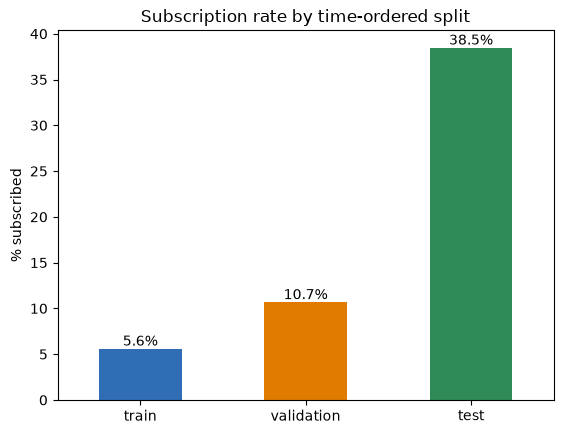

In [4]:
# Subscription rate per split: the newest customers subscribe far more often (drift).
rates = pd.Series({name: values['positive_rate'] for name, values in result['split_summary'].items()})
ax = (rates * 100).plot.bar(title='Subscription rate by time-ordered split', ylabel='% subscribed', rot=0,
                            color=['#2F6DB5', '#E07B00', '#2E8B57'])
ax.bar_label(ax.containers[0], fmt='%.1f%%');

## Step 3. Inspect the outputs

The files use the built-in XGBoost CSV format: no header, and the label in the first column for train and validation. Each training channel gets its own folder, because SageMaker reads every file under a channel's S3 prefix.

In [5]:
outputs = pd.DataFrame(
    [(name, Path(path).relative_to(Path(config['output']['processed_dir'])).as_posix(),
      round(Path(path).stat().st_size / 1024, 1)) for name, path in result['outputs'].items()],
    columns=['output', 'file', 'size_kb'])
display(outputs)

,output,file,size_kb
0,train,train/train.csv,3915.6
1,validation,validation/validation.csv,838.7
2,validation_features,batch-input/validation_features.csv,826.6
3,validation_labels,labels/validation_labels.csv,12.1
4,test_features,batch-input/test_features.csv,826.7
5,test_labels,labels/test_labels.csv,12.1
6,feature_schema,feature-schema/feature_schema.json,6.2


In [6]:
# The first train rows with the schema's column names (the file itself has no header).
schema = read_json(result['outputs']['feature_schema'])
train = read_csv(result['outputs']['train'], header=None)
train.columns = ['label'] + schema['columns']
display(train.iloc[:, :12].head())        # first 12 of the 74 columns; train.head() shows all
print('label values:', sorted(train['label'].unique().tolist()), '| feature columns:', len(schema['columns']))

,label,previously_contacted,prior_success,previous_contacts,campaign_intensity,capped_campaign,age,age_band__lt30,age_band__30_44,age_band__45_59,age_band__60plus,categorical_profile__job__admin.
0,0,0,0,0,1,1,56,0,0,1,0,0
1,0,0,0,0,1,1,57,0,0,1,0,0
2,0,0,0,0,1,1,37,0,1,0,0,0
3,0,0,0,0,1,1,40,0,1,0,0,1
4,0,0,0,0,1,1,56,0,0,1,0,0


label values: [0, 1] | feature columns: 68


In [7]:
# Lineage: which data, code and settings produced these files.
metadata = read_json(result['run_metadata'])
display(pd.Series({
    'run_id': metadata['run_id'],
    'git_commit': (metadata['code']['git_commit'] or '')[:12],
    'uncommitted_changes': metadata['code']['uncommitted_changes'],
    'raw_data_sha256': metadata['inputs']['raw_data']['sha256'][:16] + '...',
    'train_sha256': metadata['outputs']['train']['sha256'][:16] + '...',
}).to_frame('value'))

,value
run_id,20261020T193709Z-05665529
git_commit,5d9a084078b1
uncommitted_changes,True
raw_data_sha256,a0aebbad8652f762...
train_sha256,751fea235c82f18f...


---
# Part 2. S3 data lake (AWS lab)

**Before running:** start the lab, paste fresh credentials into `~/.aws/credentials` under `[bankpulse-lab]`, and run `python scripts\check_aws.py` (see issue BP-400).

The notebook picks the `bankpulse-lab` profile itself, and uses `LabRole` as the SageMaker role. Inside SageMaker Studio it uses Studio's execution role instead.

## BP-402. SageMaker session, role and bucket

- **boto3 session:** the low-level AWS connection; credentials come from the profile.
- **SageMaker session:** wraps it and knows the region and the default bucket.
- **Role:** the IAM role that SageMaker jobs and endpoints *run as*. In the lab, that's `LabRole`.
- **Default bucket:** `sagemaker-<region>-<account>`, created on first use.

**Screenshot:** this cell's output.

In [8]:
import sagemaker

from bankpulse_core.aws import lab_boto_session, lab_role, s3_uri, update_state

# Step 1: connect. Credentials come from ~/.aws via the bankpulse-lab profile; none appear here.
boto_session = lab_boto_session()
sm_session = sagemaker.Session(boto_session=boto_session)

# Step 2: the role SageMaker will assume to run training jobs, transform jobs and endpoints.
role = lab_role(boto_session)

# Step 3: the bucket and folder (prefix) that hold the whole data lake.
bucket = sm_session.default_bucket()
prefix = config['s3']['prefix']

# Step 4: save these for notebooks 02-05 (data/processed/ is git-ignored).
STATE = Path(config['output']['processed_dir']) / 'sagemaker_state.json'
update_state(STATE, region=sm_session.boto_region_name, role=role, bucket=bucket, prefix=prefix)

print('region :', sm_session.boto_region_name)
print('role   :', role)
print('bucket :', bucket)
print('lake   :', s3_uri(bucket, prefix))

sagemaker.config INFO - Not applying SDK defaults from location: C:\ProgramData\sagemaker\sagemaker\config.yaml


sagemaker.config INFO - Not applying SDK defaults from location: C:\Users\aishw\AppData\Local\sagemaker\sagemaker\config.yaml


region : us-east-1
role   : arn:aws:iam::973712293028:role/LabRole
bucket : sagemaker-us-east-1-973712293028
lake   : s3://sagemaker-us-east-1-973712293028/bank-campaign-mlops


## BP-404. Upload raw data and pipeline outputs to S3

The S3 layout mirrors the local output folders:
```
bank-campaign-mlops/
  raw/                 the original file
  train/ validation/   label-first files: the training job's two input channels
  batch-input/         feature-only files for Batch Transform
  labels/              labels for evaluation
  feature-schema/      column order + feature states, for the endpoint
  run-metadata/        lineage of the run that produced these files
```

**Screenshots:** the S3 console showing the folders, and the object details of `train/train.csv`.

In [9]:
from bankpulse_core.io import file_hash, list_objects, upload_file

processed = Path(config['output']['processed_dir'])

# Step 1: local file -> S3 URI, keeping each output's folder (train/, batch-input/, ...).
uploads = {config['data']['path']: s3_uri(bucket, prefix, 'raw', Path(config['data']['path']).name)}
for name, path in result['outputs'].items():
    uploads[path] = s3_uri(bucket, prefix, Path(path).relative_to(processed).as_posix())
uploads[result['run_metadata']] = s3_uri(bucket, prefix, 'run-metadata', 'run_metadata.json')

# Step 2: upload (boto3 uses multipart automatically for large files).
for local, uri in uploads.items():
    upload_file(local, uri)

# Step 3: check the upload is byte-identical, using the same SHA-256 the lineage recorded.
train_uri = uploads[result['outputs']['train']]
assert file_hash(train_uri) == file_hash(result['outputs']['train']), 'train.csv changed during upload'

# Step 4: save the S3 locations the next notebooks need.
update_state(STATE, s3={name: uploads[path] for name, path in result['outputs'].items()})

# Step 5: confirm each uploaded object is listed in S3.
listing = set(list_objects(s3_uri(bucket, prefix) + '/'))
display(pd.DataFrame({'s3 object': [uri.split(f'{bucket}/', 1)[1] for uri in uploads.values()],
                      'in S3': [uri in listing for uri in uploads.values()]}))
print(len(uploads), 'files uploaded; train.csv hash verified in S3')

,s3 object,in S3
0,bank-campaign-mlops/raw/bank-additional-full.csv,True
1,bank-campaign-mlops/train/train.csv,True
2,bank-campaign-mlops/validation/validation.csv,True
3,bank-campaign-mlops/batch-input/validation_fea...,True
4,bank-campaign-mlops/labels/validation_labels.csv,True
5,bank-campaign-mlops/batch-input/test_features.csv,True
6,bank-campaign-mlops/labels/test_labels.csv,True
7,bank-campaign-mlops/feature-schema/feature_sch...,True
8,bank-campaign-mlops/run-metadata/run_metadata....,True


9 files uploaded; train.csv hash verified in S3
